In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from influxdb_client_3 import InfluxDBClient3

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
HOST = "http://127.0.0.1:8182"
DATABASE = "fan_monitor"
TOKEN = "apiv3_Ynk9eheNcAjK2R9iBR7cvoLFAlQgT2YMAap8L9_SflJ-KepGFg85yDsvO1yMq35NbhlaOzZGKFj6UMHOGNs6bQ"

client = InfluxDBClient3(
    host=HOST,
    database=DATABASE,
    token=TOKEN if TOKEN else None
)

print("Connected to InfluxDB!")

Connected to InfluxDB!


In [5]:
query = """
SELECT
    time,
    current,
    freq,
    amp,
    dev
FROM fan_telemetry
WHERE time >= (
    SELECT MIN(time) + INTERVAL '10' HOUR
    FROM fan_telemetry
)
ORDER BY time ASC
"""

table = client.query(
    query=query,
    language="sql"
)

df = table.to_pandas()
df_clean = df[df["amp"] > 0].copy()

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

Data loaded successfully!
Dataset shape: (81499, 5)


In [6]:
# Chỉ giữ hai tần số làm mốc vận hành ổn định ban đầu
stable_freqs = [19.5, 21.5]

df_stable = df[df["freq"].isin(stable_freqs)].copy()

print("Số bản ghi sau khi lọc freq:", len(df_stable))
display(df_stable["freq"].value_counts().sort_index().to_frame("count"))

Số bản ghi sau khi lọc freq: 54312


,count
freq,
19.5,44793
21.5,9519


In [7]:
current_df = df_stable.dropna(subset=["current"]).copy()

print("Số bản ghi current hợp lệ:", len(current_df))
display(
    current_df["current"]
    .describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])
    .to_frame("current")
)

Số bản ghi current hợp lệ: 54312


,current
count,54312.000000
mean,4.579977
std,0.051313
min,2.380000
1%,4.470000
5%,4.510000
25%,4.560000
50%,4.570000
75%,4.600000
95%,4.670000


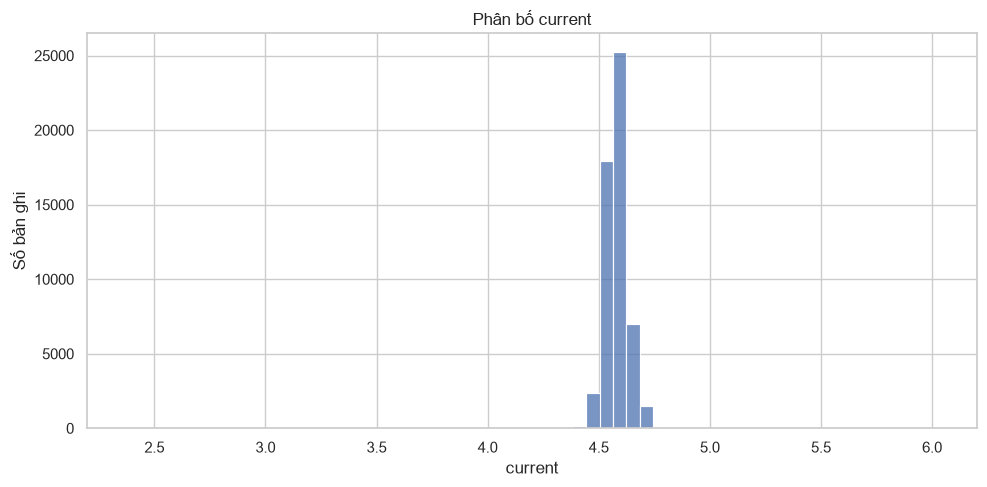

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(data=current_df, x="current", bins=60)

plt.title("Phân bố current")
plt.xlabel("current")
plt.ylabel("Số bản ghi")

plt.tight_layout()
plt.show()

In [9]:
current_stats = current_df["current"].agg(
    [
        "count",
        "mean",
        "median",
        "var",
        "std",
        "min",
        "max"
    ]
)

display(current_stats.to_frame(name="current"))

,current
count,54312.000000
mean,4.579977
median,4.570000
var,0.002633
std,0.051313
min,2.380000
max,6.020000


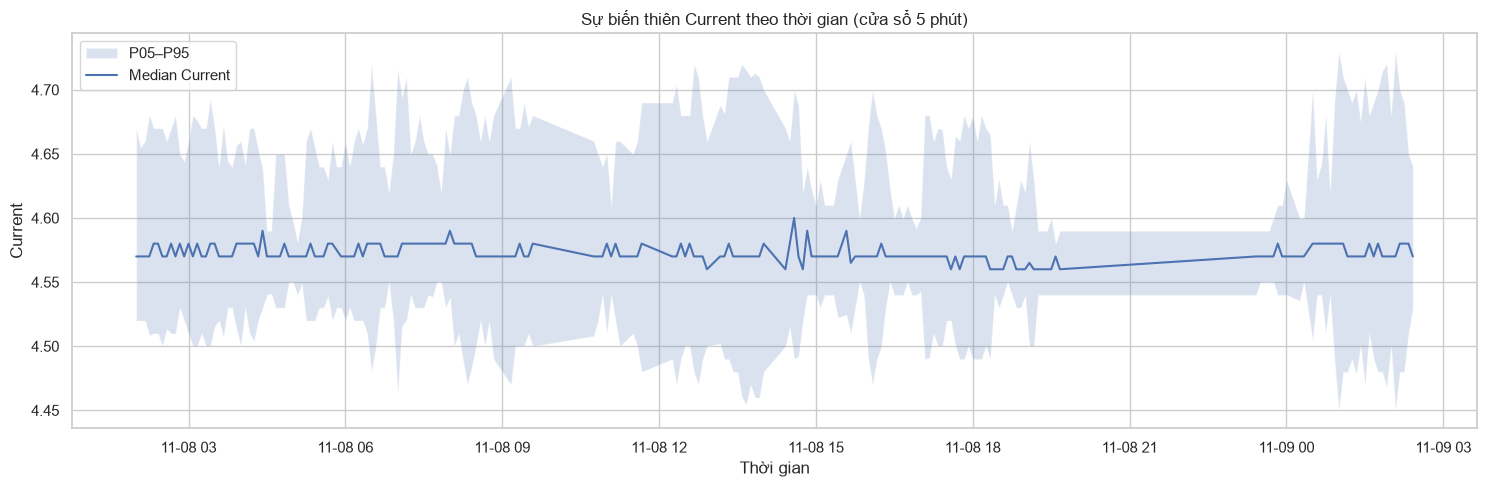

In [10]:
current_time = current_df.set_index("time").sort_index()

current_window = current_time["current"].resample("5min").agg(
    count="count",
    median="median",
    p05=lambda x: x.quantile(0.05),
    p95=lambda x: x.quantile(0.95)
)

# Chỉ giữ cửa sổ có ít nhất 100 mẫu
current_window = current_window[current_window["count"] >= 100]

plt.figure(figsize=(15, 5))

plt.fill_between(
    current_window.index,
    current_window["p05"],
    current_window["p95"],
    alpha=0.2,
    label="P05–P95"
)

plt.plot(
    current_window.index,
    current_window["median"],
    linewidth=1.5,
    label="Median Current"
)

plt.title("Sự biến thiên Current theo thời gian (cửa sổ 5 phút)")
plt.xlabel("Thời gian")
plt.ylabel("Current")
plt.legend()
plt.tight_layout()
plt.show()